# DAS7002 Big Data Technologies — PRAC 1

## Task 4: Distributed Supervised Machine Learning

This task develops a distributed classification model to predict the likelihood of arrest for reported crime incidents.

The binary `Arrest` field is used as the prediction target because it provides a clearly defined classification problem and supports evaluation using confusion matrix, precision, recall, F1-score, and ROC-AUC.

The analysis will:

- inspect and validate the target class distribution,
- prepare temporal, spatial, and categorical predictor features,
- construct a Spark ML pipeline,
- train a distributed classification model,
- evaluate predictive performance,
- analyse class imbalance and its effect on precision and recall,
- and discuss model limitations and potential bias arising from the historical crime data.

In [1]:
import os
from pathlib import Path

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

PROJECT_ROOT = Path(
    r"C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)

Project root: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002
Processed data: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\data\processed


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("DAS7002_PRAC1_Task4_SupervisedML")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)

Spark version: 3.5.6
Application: DAS7002_PRAC1_Task4_SupervisedML
Master: local[*]


In [3]:
crime_df = spark.read.parquet(
    str(PROCESSED_DIR / "crime_parquet")
)

print("Crime dataset loaded.")

Crime dataset loaded.


In [4]:
crime_df.select(
    "ID",
    "Arrest",
    "Domestic",
    "Primary Type",
    "Location Description",
    "District",
    "Community Area",
    "Latitude",
    "Longitude",
    "Crime_Hour",
    "Crime_Day_Of_Week",
    "Crime_Month",
    "Is_Weekend",
    "Year"
).printSchema()

root
 |-- ID: long (nullable = true)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Location Description: string (nullable = true)
 |-- District: integer (nullable = true)
 |-- Community Area: integer (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Crime_Hour: integer (nullable = true)
 |-- Crime_Day_Of_Week: string (nullable = true)
 |-- Crime_Month: integer (nullable = true)
 |-- Is_Weekend: boolean (nullable = true)
 |-- Year: integer (nullable = true)



In [5]:
arrest_distribution_df = (
    crime_df
    .groupBy("Arrest")
    .agg(
        F.count("*").alias("Record_Count")
    )
    .orderBy("Arrest")
)

arrest_distribution_df.show()

+------+------------+
|Arrest|Record_Count|
+------+------------+
| false|     5749900|
|  true|     2034764|
+------+------------+



In [6]:
total_records = 7_784_664

arrest_distribution_percent_df = (
    arrest_distribution_df
    .withColumn(
        "Percentage",
        F.round(
            F.col("Record_Count") / total_records * 100,
            2
        )
    )
)

arrest_distribution_percent_df.show()

+------+------------+----------+
|Arrest|Record_Count|Percentage|
+------+------------+----------+
| false|     5749900|     73.86|
|  true|     2034764|     26.14|
+------+------------+----------+



### 2.1 Target Distribution and Class Imbalance

The arrest target is imbalanced.

Of the 7,784,664 crime records, 5,749,900 (73.86%) are labelled as no arrest, while 2,034,764 (26.14%) are labelled as arrest.

This imbalance is important for model evaluation. A classifier that predicted the majority class for every observation would achieve approximately 73.86% accuracy despite having no practical ability to identify arrest cases.

Consequently, model performance will not be assessed using accuracy alone. Precision, recall, F1-score, ROC-AUC, and the confusion matrix will be used to evaluate performance, with particular attention paid to the minority arrest class.

## 3. Predictor Preparation and Missing-Value Assessment

Predictor variables are selected from information describing the offence type, location, geography, and time of occurrence.

Identifier fields are excluded because they do not represent meaningful predictive characteristics. The arrest target itself is also excluded from the feature vector to prevent target leakage.

Before constructing the Spark ML pipeline, missingness is assessed across the selected predictors so that categorical and numeric variables can be handled appropriately.

In [7]:
selected_predictors = [
    "Primary Type",
    "Location Description",
    "District",
    "Community Area",
    "Domestic",
    "Crime_Hour",
    "Crime_Day_Of_Week",
    "Crime_Month",
    "Is_Weekend",
    "Year",
    "Latitude",
    "Longitude"
]

In [8]:
missing_summary_exprs = []

for col_name in selected_predictors:
    missing_summary_exprs.append(
        F.sum(
            F.when(
                F.col(col_name).isNull(),
                1
            ).otherwise(0)
        ).alias(col_name)
    )

predictor_missing_df = crime_df.agg(
    *missing_summary_exprs
)

predictor_missing_df.show(
    truncate=False
)

+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+
|Primary Type|Location Description|District|Community Area|Domestic|Crime_Hour|Crime_Day_Of_Week|Crime_Month|Is_Weekend|Year|Latitude|Longitude|
+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+
|0           |10381               |47      |613476        |0       |0         |0                |0          |0         |0   |86848   |86848    |
+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+



In [9]:
missing_summary_exprs = []

for col_name in selected_predictors:
    missing_summary_exprs.append(
        F.sum(
            F.when(
                F.col(col_name).isNull(),
                1
            ).otherwise(0)
        ).alias(col_name)
    )

predictor_missing_df = crime_df.agg(
    *missing_summary_exprs
)

predictor_missing_df.show(
    truncate=False
)

+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+
|Primary Type|Location Description|District|Community Area|Domestic|Crime_Hour|Crime_Day_Of_Week|Crime_Month|Is_Weekend|Year|Latitude|Longitude|
+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+
|0           |10381               |47      |613476        |0       |0         |0                |0          |0         |0   |86848   |86848    |
+------------+--------------------+--------+--------------+--------+----------+-----------------+-----------+----------+----+--------+---------+



In [10]:
missing_counts = predictor_missing_df.first().asDict()

print("PREDICTOR MISSINGNESS")
print("-" * 60)

for col_name in selected_predictors:
    missing_count = missing_counts[col_name]
    missing_pct = (
        missing_count / total_records
    ) * 100

    print(
        f"{col_name:<25} "
        f"{missing_count:>10,} "
        f"({missing_pct:>6.2f}%)"
    )

PREDICTOR MISSINGNESS
------------------------------------------------------------
Primary Type                       0 (  0.00%)
Location Description          10,381 (  0.13%)
District                          47 (  0.00%)
Community Area               613,476 (  7.88%)
Domestic                           0 (  0.00%)
Crime_Hour                         0 (  0.00%)
Crime_Day_Of_Week                  0 (  0.00%)
Crime_Month                        0 (  0.00%)
Is_Weekend                         0 (  0.00%)
Year                               0 (  0.00%)
Latitude                      86,848 (  1.12%)
Longitude                     86,848 (  1.12%)


### 3.1 Missing-Value Handling Strategy

Missing predictor values are handled according to variable type rather than removing all incomplete records.

Categorical geographic and location fields are assigned an explicit `UNKNOWN` category so that records with missing administrative identifiers are retained.

Latitude and longitude contain approximately 1.12% missing values and are imputed using the median value calculated from the training data. Median imputation is preferred over mean imputation because it is less sensitive to extreme coordinate values.

This strategy preserves the majority of the dataset while avoiding unnecessary record loss.

In [11]:
model_df = (
    crime_df
    .select(
        "Arrest",
        "Primary Type",
        "Location Description",
        "District",
        "Community Area",
        "Domestic",
        "Crime_Hour",
        "Crime_Day_Of_Week",
        "Crime_Month",
        "Is_Weekend",
        "Year",
        "Latitude",
        "Longitude"
    )
    .withColumn(
        "label",
        F.col("Arrest").cast("double")
    )
    .withColumn(
        "Domestic_Num",
        F.col("Domestic").cast("double")
    )
    .withColumn(
        "Weekend_Num",
        F.col("Is_Weekend").cast("double")
    )
)

In [12]:
model_df = (
    model_df
    .withColumn(
        "District_Str",
        F.when(
            F.col("District").isNull(),
            F.lit("UNKNOWN")
        ).otherwise(
            F.col("District").cast("string")
        )
    )
    .withColumn(
        "Community_Area_Str",
        F.when(
            F.col("Community Area").isNull(),
            F.lit("UNKNOWN")
        ).otherwise(
            F.col("Community Area").cast("string")
        )
    )
    .withColumn(
        "Location_Description_Clean",
        F.when(
            F.col("Location Description").isNull(),
            F.lit("UNKNOWN")
        ).otherwise(
            F.col("Location Description")
        )
    )
)

In [13]:
model_df.select(
    "label",
    "Primary Type",
    "Location_Description_Clean",
    "District_Str",
    "Community_Area_Str",
    "Domestic_Num",
    "Crime_Hour",
    "Crime_Day_Of_Week",
    "Crime_Month",
    "Weekend_Num",
    "Year",
    "Latitude",
    "Longitude"
).printSchema()

root
 |-- label: double (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Location_Description_Clean: string (nullable = true)
 |-- District_Str: string (nullable = true)
 |-- Community_Area_Str: string (nullable = true)
 |-- Domestic_Num: double (nullable = true)
 |-- Crime_Hour: integer (nullable = true)
 |-- Crime_Day_Of_Week: string (nullable = true)
 |-- Crime_Month: integer (nullable = true)
 |-- Weekend_Num: double (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)



In [14]:
model_df.select(
    "label",
    "Primary Type",
    "Location_Description_Clean",
    "District_Str",
    "Community_Area_Str",
    "Domestic_Num",
    "Crime_Hour",
    "Crime_Day_Of_Week",
    "Crime_Month",
    "Weekend_Num",
    "Year",
    "Latitude",
    "Longitude"
).show(10, truncate=False)

+-----+-------------------+------------------------------+------------+------------------+------------+----------+-----------------+-----------+-----------+----+------------+-------------+
|label|Primary Type       |Location_Description_Clean    |District_Str|Community_Area_Str|Domestic_Num|Crime_Hour|Crime_Day_Of_Week|Crime_Month|Weekend_Num|Year|Latitude    |Longitude    |
+-----+-------------------+------------------------------+------------+------------------+------------+----------+-----------------+-----------+-----------+----+------------+-------------+
|1.0  |PROSTITUTION       |STREET                        |8           |56                |0.0         |23        |Thursday         |5          |0.0        |2005|41.807103536|-87.740697063|
|1.0  |CRIMINAL TRESPASS  |RESIDENCE                     |8           |63                |0.0         |19        |Sunday           |9          |1.0        |2005|41.798207769|-87.709818706|
|1.0  |PROSTITUTION       |STREET                      

### 3.2 Categorical Cardinality Assessment

Categorical predictors are inspected before one-hot encoding to determine how many distinct levels each variable contains.

This step is important because very high-cardinality categorical variables can substantially increase feature dimensionality and computational cost in distributed machine-learning pipelines.

In [15]:
categorical_cols = [
    "Primary Type",
    "Location_Description_Clean",
    "District_Str",
    "Community_Area_Str",
    "Crime_Day_Of_Week"
]

for col_name in categorical_cols:
    distinct_count = (
        model_df
        .select(col_name)
        .distinct()
        .count()
    )

    print(
        f"{col_name:<30} "
        f"{distinct_count:>5} distinct values"
    )

Primary Type                      36 distinct values
Location_Description_Clean       216 distinct values
District_Str                      25 distinct values
Community_Area_Str                79 distinct values
Crime_Day_Of_Week                  7 distinct values


In [16]:
(
    model_df
    .groupBy("Location_Description_Clean")
    .agg(
        F.count("*").alias("Record_Count")
    )
    .orderBy(F.desc("Record_Count"))
    .show(20, truncate=False)
)

+------------------------------+------------+
|Location_Description_Clean    |Record_Count|
+------------------------------+------------+
|STREET                        |2026828     |
|RESIDENCE                     |1305843     |
|APARTMENT                     |879342      |
|SIDEWALK                      |728865      |
|OTHER                         |270026      |
|PARKING LOT/GARAGE(NON.RESID.)|202991      |
|ALLEY                         |172812      |
|SMALL RETAIL STORE            |147164      |
|SCHOOL, PUBLIC, BUILDING      |146387      |
|RESIDENCE-GARAGE              |135543      |
|RESTAURANT                    |127259      |
|RESIDENCE PORCH/HALLWAY       |124210      |
|VEHICLE NON-COMMERCIAL        |124052      |
|GROCERY FOOD STORE            |98701       |
|DEPARTMENT STORE              |98578       |
|GAS STATION                   |86473       |
|RESIDENTIAL YARD (FRONT/BACK) |75151       |
|COMMERCIAL / BUSINESS OFFICE  |60324       |
|PARK PROPERTY                 |58

### 3.3 Categorical Feature Decision

The categorical-cardinality assessment shows that all selected variables remain computationally manageable for distributed encoding.

`Location Description` has the highest cardinality with 216 distinct categories, while the remaining categorical variables contain substantially fewer levels. Given the scale of the crime dataset, 216 categories does not create an excessive feature space.

Therefore, all selected categorical predictors are retained and encoded using `StringIndexer` and `OneHotEncoder`. Rare location categories are not manually merged because preserving the original categories retains potentially useful contextual information for arrest prediction.

## 4. Spark ML Feature Pipeline

A Spark ML preprocessing pipeline is constructed so that all transformations are learned consistently from the training data.

Categorical variables are converted to indexed categories and one-hot encoded. Missing latitude and longitude values are imputed using the median. Numeric and encoded categorical features are then assembled into a single feature vector.

Keeping preprocessing inside the pipeline also reduces the risk of information leakage between training and test datasets.

In [17]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    Imputer,
    VectorAssembler
)

In [18]:
categorical_input_cols = [
    "Primary Type",
    "Location_Description_Clean",
    "District_Str",
    "Community_Area_Str",
    "Crime_Day_Of_Week"
]

In [19]:
indexers = [
    StringIndexer(
        inputCol=col_name,
        outputCol=f"{col_name}_Index",
        handleInvalid="keep"
    )
    for col_name in categorical_input_cols
]

In [20]:
indexed_cols = [
    f"{col_name}_Index"
    for col_name in categorical_input_cols
]

In [21]:
encoded_cols = [
    f"{col_name}_OHE"
    for col_name in categorical_input_cols
]

encoder = OneHotEncoder(
    inputCols=indexed_cols,
    outputCols=encoded_cols,
    handleInvalid="keep"
)

In [22]:
imputer = Imputer(
    inputCols=[
        "Latitude",
        "Longitude"
    ],
    outputCols=[
        "Latitude_Imputed",
        "Longitude_Imputed"
    ],
    strategy="median"
)

In [23]:
numeric_feature_cols = [
    "Domestic_Num",
    "Crime_Hour",
    "Crime_Month",
    "Weekend_Num",
    "Year",
    "Latitude_Imputed",
    "Longitude_Imputed"
]

final_feature_cols = (
    encoded_cols
    + numeric_feature_cols
)

print("Encoded categorical feature groups:")
for col_name in encoded_cols:
    print(" -", col_name)

print("\nNumeric predictors:")
for col_name in numeric_feature_cols:
    print(" -", col_name)

Encoded categorical feature groups:
 - Primary Type_OHE
 - Location_Description_Clean_OHE
 - District_Str_OHE
 - Community_Area_Str_OHE
 - Crime_Day_Of_Week_OHE

Numeric predictors:
 - Domestic_Num
 - Crime_Hour
 - Crime_Month
 - Weekend_Num
 - Year
 - Latitude_Imputed
 - Longitude_Imputed


In [24]:
assembler = VectorAssembler(
    inputCols=final_feature_cols,
    outputCol="features",
    handleInvalid="keep"
)

## 5. Training and Test Split

The modelling dataset is divided into training and test subsets using an 80/20 split with a fixed random seed.

The preprocessing pipeline is fitted only on the training data. This ensures that category indexing, imputation values, and model parameters are not influenced by information from the held-out test set.

Because the arrest target is imbalanced, the class distribution is checked in both subsets before model training.

In [25]:
train_df, test_df = model_df.randomSplit(
    [0.80, 0.20],
    seed=42
)

train_df = train_df.cache()
test_df = test_df.cache()

train_count = train_df.count()
test_count = test_df.count()

print(f"Training records: {train_count:,}")
print(f"Test records:     {test_count:,}")

print(
    f"Training share:   "
    f"{(train_count / total_records) * 100:.2f}%"
)

print(
    f"Test share:       "
    f"{(test_count / total_records) * 100:.2f}%"
)

Training records: 6,228,417
Test records:     1,556,247
Training share:   80.01%
Test share:       19.99%


In [26]:
def show_class_distribution(df, dataset_name):

    distribution = (
        df
        .groupBy("label")
        .agg(
            F.count("*").alias("Record_Count")
        )
    )

    dataset_total = df.count()

    distribution = (
        distribution
        .withColumn(
            "Percentage",
            F.round(
                F.col("Record_Count")
                / dataset_total
                * 100,
                2
            )
        )
        .orderBy("label")
    )

    print(f"\n{dataset_name.upper()} CLASS DISTRIBUTION")
    print("-" * 45)

    distribution.show(truncate=False)


show_class_distribution(
    train_df,
    "Training"
)

show_class_distribution(
    test_df,
    "Test"
)


TRAINING CLASS DISTRIBUTION
---------------------------------------------
+-----+------------+----------+
|label|Record_Count|Percentage|
+-----+------------+----------+
|0.0  |4599894     |73.85     |
|1.0  |1628523     |26.15     |
+-----+------------+----------+


TEST CLASS DISTRIBUTION
---------------------------------------------
+-----+------------+----------+
|label|Record_Count|Percentage|
+-----+------------+----------+
|0.0  |1150006     |73.9      |
|1.0  |406241      |26.1      |
+-----+------------+----------+



### 5.1 Training/Test Distribution Validation

The 80/20 split produced 6,228,417 training records and 1,556,247 test records.

Class proportions remain highly consistent between the two subsets. Arrest cases account for approximately 26.15% of the training data and 26.10% of the test data, closely matching the 26.14% proportion observed in the complete dataset.

This similarity indicates that the random split produced representative training and test populations and allows model performance to be evaluated on a held-out dataset with a comparable class distribution.

## 6. Baseline Distributed Random Forest

A Random Forest classifier is used as the primary distributed supervised-learning algorithm.

Random Forest is suitable for this analysis because it can model nonlinear relationships and interactions across categorical, temporal, spatial, and contextual predictors.

A baseline model is first trained without class weighting. Its performance will then be examined using metrics that account for the imbalanced arrest target.

In [27]:
from pyspark.ml.classification import RandomForestClassifier

In [28]:
rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    predictionCol="prediction",
    probabilityCol="probability",
    rawPredictionCol="rawPrediction",
    numTrees=50,
    maxDepth=10,
    seed=42
)

In [29]:
rf_pipeline = Pipeline(
    stages=(
        indexers
        + [
            encoder,
            imputer,
            assembler,
            rf
        ]
    )
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [30]:
rf_pipeline_model = rf_pipeline.fit(
    train_df
)

print("Baseline Random Forest trained successfully.")

Baseline Random Forest trained successfully.


In [31]:
RF_MODEL_PATH = (
    MODELS_DIR / "task4_baseline_random_forest_pipeline"
)

rf_pipeline_model.write().overwrite().save(
    str(RF_MODEL_PATH)
)

print(
    "Baseline Random Forest model saved to:",
    RF_MODEL_PATH
)

Baseline Random Forest model saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\models\task4_baseline_random_forest_pipeline


In [32]:
rf_predictions = (
    rf_pipeline_model
    .transform(test_df)
    .select(
        "label",
        "prediction",
        "probability",
        "rawPrediction"
    )
)

print("Prediction DataFrame created successfully.")

Prediction DataFrame created successfully.


In [33]:
from pyspark import StorageLevel

rf_predictions = rf_predictions.persist(
    StorageLevel.DISK_ONLY
)

print(
    "Predictions configured for DISK_ONLY persistence."
)

Predictions configured for DISK_ONLY persistence.


In [34]:
prediction_count = rf_predictions.count()

print(
    f"Test predictions generated: "
    f"{prediction_count:,}"
)

Test predictions generated: 1,556,247


In [35]:
rf_predictions.show(
    10,
    truncate=False
)

+-----+----------+----------------------------------------+---------------------------------------+
|label|prediction|probability                             |rawPrediction                          |
+-----+----------+----------------------------------------+---------------------------------------+
|0.0  |0.0       |[0.7623616820465436,0.23763831795345636]|[38.11808410232719,11.881915897672819] |
|0.0  |0.0       |[0.7261821439151582,0.27381785608484177]|[36.30910719575792,13.69089280424209]  |
|0.0  |0.0       |[0.7261821439151582,0.27381785608484177]|[36.30910719575792,13.69089280424209]  |
|0.0  |0.0       |[0.7599280589916274,0.24007194100837265]|[37.99640294958137,12.003597050418634] |
|0.0  |0.0       |[0.7306974231308054,0.26930257686919457]|[36.53487115654028,13.46512884345973]  |
|0.0  |0.0       |[0.7185444773522568,0.2814555226477431] |[35.92722386761285,14.07277613238716]  |
|0.0  |0.0       |[0.7179913868839791,0.2820086131160209] |[35.89956934419896,14.100430655801047] |


## 7. Baseline Random Forest Evaluation

The baseline Random Forest is evaluated on the held-out test dataset.

Because the target is imbalanced, performance is assessed using multiple metrics rather than accuracy alone. The evaluation includes:

- confusion matrix,
- accuracy,
- precision,
- recall,
- F1-score,
- and ROC-AUC.

For this analysis, the positive class (`1.0`) represents an arrest.

In [36]:
confusion_matrix_df = (
    rf_predictions
    .groupBy(
        "label",
        "prediction"
    )
    .agg(
        F.count("*").alias("Count")
    )
    .orderBy(
        "label",
        "prediction"
    )
)

confusion_matrix_df.show(truncate=False)

+-----+----------+-------+
|label|prediction|Count  |
+-----+----------+-------+
|0.0  |0.0       |1146767|
|0.0  |1.0       |3239   |
|1.0  |0.0       |237600 |
|1.0  |1.0       |168641 |
+-----+----------+-------+



In [37]:
confusion_counts = {
    (row["label"], row["prediction"]): row["Count"]
    for row in confusion_matrix_df.collect()
}

TN = confusion_counts.get((0.0, 0.0), 0)
FP = confusion_counts.get((0.0, 1.0), 0)
FN = confusion_counts.get((1.0, 0.0), 0)
TP = confusion_counts.get((1.0, 1.0), 0)

print("CONFUSION MATRIX COUNTS")
print("-" * 45)

print(f"True Negatives  (TN): {TN:,}")
print(f"False Positives (FP): {FP:,}")
print(f"False Negatives (FN): {FN:,}")
print(f"True Positives  (TP): {TP:,}")

CONFUSION MATRIX COUNTS
---------------------------------------------
True Negatives  (TN): 1,146,767
False Positives (FP): 3,239
False Negatives (FN): 237,600
True Positives  (TP): 168,641


In [38]:
accuracy = (
    (TP + TN)
    / (TP + TN + FP + FN)
)

precision = (
    TP / (TP + FP)
    if (TP + FP) > 0
    else 0
)

recall = (
    TP / (TP + FN)
    if (TP + FN) > 0
    else 0
)

f1 = (
    2 * precision * recall
    / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print("BASELINE RANDOM FOREST METRICS")
print("-" * 45)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

BASELINE RANDOM FOREST METRICS
---------------------------------------------
Accuracy : 0.8452
Precision: 0.9812
Recall   : 0.4151
F1-score : 0.5834


In [39]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

roc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

roc_auc = roc_evaluator.evaluate(
    rf_predictions
)

print(
    f"ROC-AUC: {roc_auc:.4f}"
)

ROC-AUC: 0.8643


In [40]:
pr_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

pr_auc = pr_evaluator.evaluate(
    rf_predictions
)

print(
    f"PR-AUC: {pr_auc:.4f}"
)

PR-AUC: 0.7921


### 7.1 Baseline Model Interpretation

The baseline Random Forest achieves an overall accuracy of 0.8452, exceeding the 73.86% majority-class baseline. Its ROC-AUC of 0.8643 and PR-AUC of 0.7921 indicate strong discriminatory performance on the held-out test dataset.

However, performance differs considerably between precision and recall for the minority arrest class.

Precision is extremely high at 0.9812, meaning that when the baseline model predicts an arrest, the prediction is correct in approximately 98% of cases. Recall is lower at 0.4151, indicating that the model identifies approximately 41.5% of actual arrest cases.

The confusion matrix reinforces this imbalance. The baseline classifier produces only 3,239 false-positive arrest predictions but fails to identify 237,600 actual arrest cases.

The resulting F1-score of 0.5834 demonstrates why accuracy alone is insufficient for evaluating this imbalanced classification problem. Although the baseline classifier performs strongly overall, its conservative decision boundary limits minority-class recall.

## 8. Class-Weighted Random Forest

The baseline model demonstrates strong precision but comparatively low recall for arrest cases. This suggests that the majority no-arrest class influences the default decision boundary.

To investigate the effect of class imbalance, a weighted Random Forest is trained in which minority arrest observations receive a larger training weight.

The weighted model is compared with the unweighted baseline to determine whether improved minority-class recall can be achieved and what effect this has on precision.

In [41]:
train_negative = 4_599_894
train_positive = 1_628_523

positive_weight = (
    train_negative / train_positive
)

print(
    f"Positive-class weight: "
    f"{positive_weight:.4f}"
)

Positive-class weight: 2.8246


In [42]:
weighted_train_df = (
    train_df
    .withColumn(
        "classWeight",
        F.when(
            F.col("label") == 1.0,
            F.lit(positive_weight)
        ).otherwise(
            F.lit(1.0)
        )
    )
)

weighted_train_df.select(
    "label",
    "classWeight"
).show(10)

+-----+-----------+
|label|classWeight|
+-----+-----------+
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
|  0.0|        1.0|
+-----+-----------+
only showing top 10 rows



### 8.1 Weighted Random Forest Training

A second Random Forest model is trained using inverse class weighting.

No-arrest observations receive a weight of 1.0, while arrest observations receive a larger weight of approximately 2.8246. This increases the influence of the minority arrest class during model training.

The objective is not necessarily to maximise accuracy, but to determine whether recall for arrest cases can be improved while observing the resulting precision trade-off.

In [43]:
weighted_rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    predictionCol="prediction",
    probabilityCol="probability",
    rawPredictionCol="rawPrediction",
    weightCol="classWeight",
    numTrees=50,
    maxDepth=10,
    seed=42
)

In [44]:
weighted_rf_pipeline = Pipeline(
    stages=(
        indexers
        + [
            encoder,
            imputer,
            assembler,
            weighted_rf
        ]
    )
)

print("Weighted Random Forest pipeline created successfully.")

Weighted Random Forest pipeline created successfully.


In [45]:
weighted_rf_pipeline_model = (
    weighted_rf_pipeline.fit(
        weighted_train_df
    )
)

print("Weighted Random Forest trained successfully.")

Weighted Random Forest trained successfully.


In [46]:
WEIGHTED_RF_MODEL_PATH = (
    MODELS_DIR / "task4_weighted_random_forest_pipeline"
)

weighted_rf_pipeline_model.write().overwrite().save(
    str(WEIGHTED_RF_MODEL_PATH)
)

print(
    "Weighted Random Forest model saved to:",
    WEIGHTED_RF_MODEL_PATH
)

Weighted Random Forest model saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\models\task4_weighted_random_forest_pipeline


In [47]:
weighted_rf_predictions = (
    weighted_rf_pipeline_model
    .transform(test_df)
    .select(
        "label",
        "prediction",
        "probability",
        "rawPrediction"
    )
)

print("Weighted prediction DataFrame created successfully.")

Weighted prediction DataFrame created successfully.


In [48]:
from pyspark import StorageLevel

weighted_rf_predictions = (
    weighted_rf_predictions.persist(
        StorageLevel.DISK_ONLY
    )
)

print(
    "Weighted predictions configured for DISK_ONLY persistence."
)

Weighted predictions configured for DISK_ONLY persistence.


In [49]:
weighted_prediction_count = (
    weighted_rf_predictions.count()
)

print(
    f"Weighted test predictions generated: "
    f"{weighted_prediction_count:,}"
)

Weighted test predictions generated: 1,556,247


In [50]:
weighted_confusion_matrix_df = (
    weighted_rf_predictions
    .groupBy(
        "label",
        "prediction"
    )
    .agg(
        F.count("*").alias("Count")
    )
    .orderBy(
        "label",
        "prediction"
    )
)

weighted_confusion_matrix_df.show(truncate=False)

+-----+----------+-------+
|label|prediction|Count  |
+-----+----------+-------+
|0.0  |0.0       |1019119|
|0.0  |1.0       |130887 |
|1.0  |0.0       |130362 |
|1.0  |1.0       |275879 |
+-----+----------+-------+



In [51]:
weighted_confusion_counts = {
    (row["label"], row["prediction"]): row["Count"]
    for row in weighted_confusion_matrix_df.collect()
}

WTN = weighted_confusion_counts.get((0.0, 0.0), 0)
WFP = weighted_confusion_counts.get((0.0, 1.0), 0)
WFN = weighted_confusion_counts.get((1.0, 0.0), 0)
WTP = weighted_confusion_counts.get((1.0, 1.0), 0)

print("WEIGHTED CONFUSION MATRIX COUNTS")
print("-" * 50)

print(f"True Negatives  (TN): {WTN:,}")
print(f"False Positives (FP): {WFP:,}")
print(f"False Negatives (FN): {WFN:,}")
print(f"True Positives  (TP): {WTP:,}")

WEIGHTED CONFUSION MATRIX COUNTS
--------------------------------------------------
True Negatives  (TN): 1,019,119
False Positives (FP): 130,887
False Negatives (FN): 130,362
True Positives  (TP): 275,879


In [52]:
weighted_accuracy = (
    (WTP + WTN)
    / (WTP + WTN + WFP + WFN)
)

weighted_precision = (
    WTP / (WTP + WFP)
    if (WTP + WFP) > 0
    else 0
)

weighted_recall = (
    WTP / (WTP + WFN)
    if (WTP + WFN) > 0
    else 0
)

weighted_f1 = (
    2 * weighted_precision * weighted_recall
    / (weighted_precision + weighted_recall)
    if (weighted_precision + weighted_recall) > 0
    else 0
)

print("WEIGHTED RANDOM FOREST METRICS")
print("-" * 50)

print(f"Accuracy : {weighted_accuracy:.4f}")
print(f"Precision: {weighted_precision:.4f}")
print(f"Recall   : {weighted_recall:.4f}")
print(f"F1-score : {weighted_f1:.4f}")

WEIGHTED RANDOM FOREST METRICS
--------------------------------------------------
Accuracy : 0.8321
Precision: 0.6782
Recall   : 0.6791
F1-score : 0.6787


In [53]:
weighted_roc_auc = roc_evaluator.evaluate(
    weighted_rf_predictions
)

weighted_pr_auc = pr_evaluator.evaluate(
    weighted_rf_predictions
)

print(
    f"ROC-AUC: {weighted_roc_auc:.4f}"
)

print(
    f"PR-AUC : {weighted_pr_auc:.4f}"
)

ROC-AUC: 0.8695
PR-AUC : 0.7915


In [54]:
print("BASELINE VS WEIGHTED RANDOM FOREST")
print("-" * 65)

print(
    f"{'Metric':<15}"
    f"{'Baseline':>15}"
    f"{'Weighted':>15}"
)

print("-" * 65)

print(
    f"{'Accuracy':<15}"
    f"{accuracy:>15.4f}"
    f"{weighted_accuracy:>15.4f}"
)

print(
    f"{'Precision':<15}"
    f"{precision:>15.4f}"
    f"{weighted_precision:>15.4f}"
)

print(
    f"{'Recall':<15}"
    f"{recall:>15.4f}"
    f"{weighted_recall:>15.4f}"
)

print(
    f"{'F1-score':<15}"
    f"{f1:>15.4f}"
    f"{weighted_f1:>15.4f}"
)

print(
    f"{'ROC-AUC':<15}"
    f"{roc_auc:>15.4f}"
    f"{weighted_roc_auc:>15.4f}"
)

print(
    f"{'PR-AUC':<15}"
    f"{pr_auc:>15.4f}"
    f"{weighted_pr_auc:>15.4f}"
)

BASELINE VS WEIGHTED RANDOM FOREST
-----------------------------------------------------------------
Metric                Baseline       Weighted
-----------------------------------------------------------------
Accuracy                0.8452         0.8321
Precision               0.9812         0.6782
Recall                  0.4151         0.6791
F1-score                0.5834         0.6787
ROC-AUC                 0.8643         0.8695
PR-AUC                  0.7921         0.7915


### 8.2 Effect of Class Weighting

Class weighting substantially changes the behaviour of the Random Forest classifier.

The baseline model strongly favours precision, achieving a precision of 0.9812 but a recall of only 0.4151. After applying class weighting, recall increases to 0.6791, meaning that the weighted model identifies approximately 68% of actual arrest cases.

True-positive predictions increase from 168,641 to 275,879, while false negatives decrease from 237,600 to 130,362. This represents a substantial improvement in sensitivity to the minority arrest class.

The increase in recall is accompanied by a reduction in precision from 0.9812 to 0.6782. False-positive predictions increase from 3,239 to 130,887 as the classifier becomes more willing to predict the minority class.

F1-score nevertheless improves from 0.5834 to 0.6787, indicating a better balance between precision and recall. Accuracy decreases moderately from 0.8452 to 0.8321.

ROC-AUC increases slightly from 0.8643 to 0.8695, whereas PR-AUC remains broadly stable, changing from 0.7921 to 0.7915.

These results demonstrate that class weighting primarily changes the classification threshold behaviour rather than producing a large improvement in ranking performance. The weighted model sacrifices some majority-class accuracy and precision in exchange for substantially greater arrest-case recall.

### 8.3 Baseline and Weighted Model Comparison

| Metric | Baseline RF | Weighted RF |
|---|---:|---:|
| Accuracy | 0.8452 | 0.8321 |
| Precision | 0.9812 | 0.6782 |
| Recall | 0.4151 | 0.6791 |
| F1-score | 0.5834 | 0.6787 |
| ROC-AUC | 0.8643 | 0.8695 |
| PR-AUC | 0.7921 | 0.7915 |

## 9. ROC Curve Comparison

ROC curves are used to compare the discrimination performance of the baseline and class-weighted Random Forest classifiers across classification thresholds.

The reported ROC-AUC values are calculated using the complete held-out test dataset. For visualisation, a reproducible sample of test predictions is used to avoid transferring the entire 1.56 million-row prediction dataset from Spark to local memory.

The sampled curves therefore provide a visual representation of model behaviour, while the full-dataset ROC-AUC values remain the primary quantitative evaluation measures.

In [56]:
from pyspark.ml.functions import vector_to_array

roc_sample_fraction = 0.10

baseline_roc_sample = (
    rf_predictions
    .select(
        "label",
        vector_to_array("probability")[1].alias(
            "Arrest_Probability"
        )
    )
    .sample(
        withReplacement=False,
        fraction=roc_sample_fraction,
        seed=42
    )
    .toPandas()
)

weighted_roc_sample = (
    weighted_rf_predictions
    .select(
        "label",
        vector_to_array("probability")[1].alias(
            "Arrest_Probability"
        )
    )
    .sample(
        withReplacement=False,
        fraction=roc_sample_fraction,
        seed=42
    )
    .toPandas()
)

print(
    "Baseline ROC sample:",
    f"{len(baseline_roc_sample):,}"
)

print(
    "Weighted ROC sample:",
    f"{len(weighted_roc_sample):,}"
)

Baseline ROC sample: 156,232
Weighted ROC sample: 156,232


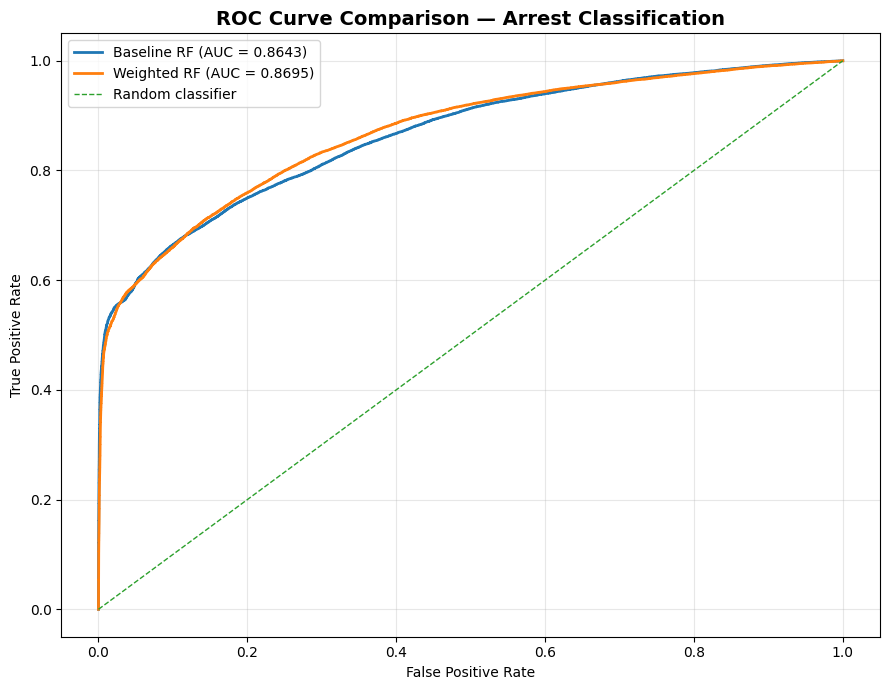

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task4_roc_curve_baseline_vs_weighted_rf.png


In [58]:
import numpy as np
import matplotlib.pyplot as plt


def calculate_roc_curve(df):
    y_true = df["label"].to_numpy()
    y_score = df["Arrest_Probability"].to_numpy()

    order = np.argsort(-y_score)

    y_true = y_true[order]
    y_score = y_score[order]

    positives = np.sum(y_true == 1)
    negatives = np.sum(y_true == 0)

    true_positives = np.cumsum(
        y_true == 1
    )

    false_positives = np.cumsum(
        y_true == 0
    )

    tpr = true_positives / positives
    fpr = false_positives / negatives

    tpr = np.insert(tpr, 0, 0)
    fpr = np.insert(fpr, 0, 0)

    return fpr, tpr


baseline_fpr, baseline_tpr = (
    calculate_roc_curve(
        baseline_roc_sample
    )
)

weighted_fpr, weighted_tpr = (
    calculate_roc_curve(
        weighted_roc_sample
    )
)


plt.figure(figsize=(9, 7))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    linewidth=2,
    label=f"Baseline RF (AUC = {roc_auc:.4f})"
)

plt.plot(
    weighted_fpr,
    weighted_tpr,
    linewidth=2,
    label=(
        f"Weighted RF "
        f"(AUC = {weighted_roc_auc:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison — Arrest Classification",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

ROC_FIGURE_PATH = (
    FIGURES_DIR
    / "task4_roc_curve_baseline_vs_weighted_rf.png"
)

plt.savefig(
    ROC_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    ROC_FIGURE_PATH
)

### 9.1 ROC Curve Interpretation

Both Random Forest models demonstrate strong discrimination between arrest and non-arrest cases, with ROC curves positioned substantially above the random-classifier diagonal.

The baseline model achieves a full-test ROC-AUC of 0.8643, while the class-weighted model achieves a slightly higher ROC-AUC of 0.8695. This indicates that class weighting preserves, and marginally improves, the model's overall ability to rank arrest cases above non-arrest cases.

The difference in ROC-AUC is relatively small compared with the change in threshold-dependent classification performance. Recall increases from 0.4151 to 0.6791 and F1-score increases from 0.5834 to 0.6787, while precision decreases from 0.9812 to 0.6782.

The principal effect of class weighting is therefore a redistribution of classification errors toward greater minority-class sensitivity rather than a substantial change in overall ranking ability.

### 9.2 Confusion-Matrix Comparison

The confusion matrices provide a direct view of how class weighting changes the allocation of classification errors.

The baseline model is compared with the weighted model using the complete held-out test dataset.

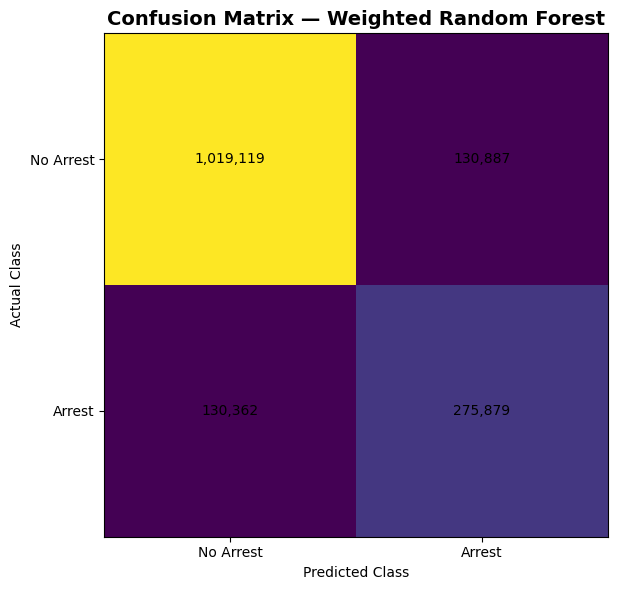

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task4_weighted_rf_confusion_matrix.png


In [61]:
import matplotlib.pyplot as plt
import numpy as np


baseline_cm = np.array([
    [TN, FP],
    [FN, TP]
])

weighted_cm = np.array([
    [WTN, WFP],
    [WFN, WTP]
])


fig, ax = plt.subplots(figsize=(7, 6))

image = ax.imshow(weighted_cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    ["No Arrest", "Arrest"]
)

ax.set_yticklabels(
    ["No Arrest", "Arrest"]
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_title(
    "Confusion Matrix — Weighted Random Forest",
    fontsize=14,
    fontweight="bold"
)

for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            f"{weighted_cm[i, j]:,}",
            ha="center",
            va="center"
        )

plt.tight_layout()

CM_FIGURE_PATH = (
    FIGURES_DIR
    / "task4_weighted_rf_confusion_matrix.png"
)

plt.savefig(
    CM_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    CM_FIGURE_PATH
)

## 10. Model Limitations, Bias, and Interpretation

Although the weighted Random Forest improves minority-class recall, the model should not be interpreted as predicting whether an arrest *should* occur. It predicts patterns present in historical police records.

The arrest label is influenced not only by offence characteristics but also by policing practices, enforcement intensity, reporting behaviour, geographic deployment, and historical operational priorities. As a result, patterns learned by the model may partly reflect institutional behaviour rather than underlying criminality alone.

Class imbalance also materially affects model behaviour. The baseline Random Forest strongly favours the majority no-arrest class, producing very high precision but low recall for arrest cases. Class weighting improves recall and F1-score by giving minority arrest observations greater influence during training, but this increases false-positive predictions and lowers precision.

Several predictors also require careful interpretation. Variables such as district, community area, location description, and geographic coordinates may act as proxies for broader neighbourhood or policing patterns. Their predictive usefulness therefore does not imply a causal relationship between location and arrest likelihood.

The model is evaluated on a random hold-out sample drawn from the same historical dataset. Consequently, the reported metrics demonstrate within-dataset predictive performance rather than guaranteed performance on future crime records or under changed policing policies.

Future work could evaluate temporal hold-out validation, alternative classifiers such as Gradient-Boosted Trees, threshold tuning, probability calibration, and fairness analysis across geographic or demographic groups where appropriate data are available.

## 11. Task 4 Summary

Task 4 developed a distributed Spark ML classification pipeline to predict the likelihood of arrest from approximately 7.8 million Chicago crime records.

The modelling pipeline incorporated categorical, temporal, spatial, and contextual predictors. Categorical features were indexed and one-hot encoded, missing geographic coordinates were median-imputed, and all predictors were assembled into a Spark ML feature vector.

The target was moderately imbalanced, with arrest cases representing approximately 26% of all records. An 80/20 training and test split preserved a similar class distribution across both datasets.

The baseline Random Forest achieved an accuracy of 0.8452, ROC-AUC of 0.8643, and PR-AUC of 0.7921. However, arrest recall was limited to 0.4151 despite a very high precision of 0.9812.

A class-weighted Random Forest was therefore evaluated using a positive-class weight of approximately 2.8246. The weighted classifier increased recall to 0.6791 and F1-score to 0.6787, while precision decreased to 0.6782.

Accuracy decreased moderately to 0.8321, while ROC-AUC increased slightly to 0.8695 and PR-AUC remained broadly stable at 0.7915.

The results demonstrate the precision–recall trade-off introduced by class weighting. For an imbalanced arrest-classification problem, the weighted model provides substantially greater sensitivity to arrest cases, although this improvement comes at the cost of additional false-positive predictions.

The analysis also highlights the importance of historical-data bias, class imbalance, and cautious interpretation of predictive policing-related variables.

In [63]:
print("TASK 4 FINAL VALIDATION")
print("-" * 65)

print(
    f"Total crime records:               "
    f"{total_records:,}"
)

print(
    f"Training records:                  "
    f"{train_count:,}"
)

print(
    f"Test records:                      "
    f"{test_count:,}"
)

print(
    f"Training arrest share:             "
    f"{(train_positive / train_count) * 100:.2f}%"
)

test_positive = (
    test_df
    .filter(F.col("label") == 1.0)
    .count()
)

print(
    f"Test arrest share:                 "
    f"{(test_positive / test_count) * 100:.2f}%"
)

print(
    f"Positive-class weight:             "
    f"{positive_weight:.4f}"
)

print()
print("BASELINE RANDOM FOREST")
print("-" * 65)

print(f"Accuracy:                          {accuracy:.4f}")
print(f"Precision:                         {precision:.4f}")
print(f"Recall:                            {recall:.4f}")
print(f"F1-score:                          {f1:.4f}")
print(f"ROC-AUC:                           {roc_auc:.4f}")
print(f"PR-AUC:                            {pr_auc:.4f}")

print()
print("WEIGHTED RANDOM FOREST")
print("-" * 65)

print(
    f"Accuracy:                          "
    f"{weighted_accuracy:.4f}"
)

print(
    f"Precision:                         "
    f"{weighted_precision:.4f}"
)

print(
    f"Recall:                            "
    f"{weighted_recall:.4f}"
)

print(
    f"F1-score:                          "
    f"{weighted_f1:.4f}"
)

print(
    f"ROC-AUC:                           "
    f"{weighted_roc_auc:.4f}"
)

print(
    f"PR-AUC:                            "
    f"{weighted_pr_auc:.4f}"
)

print("-" * 65)
print(
    "Task 4 supervised ML analysis "
    "completed successfully."
)

TASK 4 FINAL VALIDATION
-----------------------------------------------------------------
Total crime records:               7,784,664
Training records:                  6,228,417
Test records:                      1,556,247
Training arrest share:             26.15%
Test arrest share:                 26.10%
Positive-class weight:             2.8246

BASELINE RANDOM FOREST
-----------------------------------------------------------------
Accuracy:                          0.8452
Precision:                         0.9812
Recall:                            0.4151
F1-score:                          0.5834
ROC-AUC:                           0.8643
PR-AUC:                            0.7921

WEIGHTED RANDOM FOREST
-----------------------------------------------------------------
Accuracy:                          0.8321
Precision:                         0.6782
Recall:                            0.6791
F1-score:                          0.6787
ROC-AUC:                           0.8695
PR-AUC: